# Fit GaussianImage to an arbitrary image

Uses `my_utils.py` -- a self-contained, single-file rewrite of the relevant
parts of https://github.com/Xinjie-Q/GaussianImage (fitting only, no
VQ/compression codec), with the differentiable 2D Gaussian rasterizer
reimplemented directly in PyTorch instead of the paper's `gsplat` CUDA
extension.

**No `gsplat` package, no CUDA toolkit / compiler, no custom extension
build.** Runs on GPU (fast) or CPU (fine for small `num_points` / small
images). Make sure `my_utils.py` is in the same folder as this notebook.


# How GaussianImage renders and trains

A `GaussianImage_Cholesky` model represents one image as `N` 2D Gaussians. Each
Gaussian `n` carries 8 learnable numbers:

- center: $(\mu x_n, \mu y_n)$
- covariance shape: Cholesky vector $(l1_n, l2_n, l3_n)$
- weighted color: $(r'_n, g'_n, b'_n)$

---

## Rendering

Rendering means: given the current N×8 parameters, produce the full
$H \times W$ RGB image. This happens every time `model.forward()` is called
(once per training step, and once at the end to inspect the result).

**Step 1 — map raw parameters into valid ranges.**
Centers are unconstrained internally and passed through `tanh` to land in
$(-1, 1)$:
$$\mu_n = \tanh(\_xyz_n)$$
Cholesky elements get a fixed offset (`cholesky_bound = [0.5, 0, 0.5]`) so the
diagonal terms $l1_n, l3_n$ never sit at exactly 0.

**Step 2 — build each Gaussian's covariance matrix.**
$$L_n = \begin{bmatrix} l1_n & 0 \\ l2_n & l3_n \end{bmatrix}, \qquad
\Sigma_n = L_n L_n^\top$$
This construction guarantees $\Sigma_n$ is always a valid covariance matrix —
no gradient step can ever make it invalid.

**Step 3 — project onto the pixel grid and bin into tiles.**
`project_gaussians_2d` converts each Gaussian's (normalized) center and
covariance into pixel space, and figures out which $16\times16$ image tiles
its footprint overlaps (`BLOCK_H`, `BLOCK_W`). Only those tiles will need to
evaluate that Gaussian — this is what makes rendering fast even with tens of
thousands of Gaussians.

**Step 4 — for every pixel, compute each nearby Gaussian's weight.**
For pixel $p=(x,y)$ and a Gaussian whose tile it falls in:
$$d_n = p - \mu_n, \qquad
\sigma_n(p) = \tfrac{1}{2}\, d_n^\top \Sigma_n^{-1} d_n, \qquad
w_n(p) = \exp(-\sigma_n(p))$$
$w_n(p) = 1$ exactly at the Gaussian's center and decays smoothly away from it,
at a rate set by $\Sigma_n$.

**Step 5 — accumulate (sum) every contribution at that pixel.**
$$C(p) = \sum_{n} c'_n \cdot w_n(p)$$
This is `rasterize_gaussians_sum`. There is no depth sorting and no
occlusion — every Gaussian reaching a pixel just adds its color in, scaled by
its own weight. This additive rule (rather than classic alpha-blending) is
what the paper calls *accumulated blending*.

**Step 6 — clamp.**
$$C_{\text{final}}(p) = \text{clamp}\big(C(p),\ 0,\ 1\big)$$
Individual Gaussians are never clamped mid-sum (so they can even carry
negative or >1 color values to cancel each other out and sharpen edges) —
only the final summed image is clamped, once.

Output: an $H \times W \times 3$ image, reshaped to `[1, 3, H, W]`.

---

## Training

Training means: starting from randomly initialized parameters, repeatedly
render the current image and nudge all 8,000 (or however many) numbers so the
rendered image gets closer to the target photo.

**Step 0 — initialize.**
- Centers: random points, mapped through `atanh` so their post-`tanh` position
  is uniform in $(-1,1)$.
- Cholesky vector: random in $(0,1)$ per component.
- Color coefficients: random in $(0,1)$ per channel.
- Opacity: fixed at 1 for every Gaussian (not learned in the base model).
- Optimizer: Adam, learning rate `lr` (default $10^{-3}$).
- Scheduler: `StepLR`, halves the learning rate every 20,000 steps.

**Step 1 — render.**
Run the full rendering pipeline above (Steps 1–6) to get the current
reconstruction $C_{\text{final}}$ for the *entire* image at once — there's no
batching over pixels or patches; every step is a full-image forward pass.

**Step 2 — compute the loss.**
Plain MSE between the rendered image and the ground-truth image:
$$\mathcal{L} = \text{MSE}\big(C_{\text{final}},\ \text{gt\_image}\big)$$
(the paper's ablations found L2/MSE works best of the loss functions they
tried for this task).

**Step 3 — backpropagate.**
`loss.backward()` computes $\partial\mathcal{L}/\partial\theta$ for every
learnable parameter $\theta$ — every $\mu_n$, every $(l1_n,l2_n,l3_n)$, every
$c'_n$ — via ordinary autograd through Steps 1–6 of rendering.

**Step 4 — update parameters.**
`optimizer.step()` applies one Adam update to every parameter using its
gradient; `optimizer.zero_grad()` then clears gradients for the next
iteration.

**Step 5 — decay the learning rate.**
`scheduler.step()` — the learning rate is halved every 20,000 steps.

**Step 6 — log and repeat.**
Track loss and PSNR ($\text{PSNR} = 10\log_{10}(1/\text{MSE})$), optionally
snapshot the current render periodically for a progress GIF/plot, and go back
to Step 1. This repeats for `iterations` steps (the paper uses 50,000 for
full fidelity; the training loop below defaults to fewer for
quick experiments).

**What actually changes over training, intuitively:**
- Centers drift toward image regions that most reduce the loss (edges,
  textured areas end up with denser Gaussians).
- Covariances stretch/rotate/shrink — large flat regions get a few big,
  round Gaussians; fine detail gets many small, thin ones.
- Colors adjust so that, once summed with all overlapping neighbors, the
  local pixel colors match the target — including occasionally going
  negative or >1 to let two overlapping blobs cancel and sharpen an edge
  neither could produce alone.

## 1. Setup


In [4]:
!pip install imageio[ffmpeg] -q

In [5]:
!pip install ninja -q
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2024 NVIDIA Corporation
Built on Tue_Oct_29_23:50:19_PDT_2024
Cuda compilation tools, release 12.6, V12.6.85
Build cuda_12.6.r12.6/compiler.35059454_0


In [6]:
import torch
print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    print("No GPU found -- running on CPU. Fine for small num_points/images; "
          "reduce NUM_POINTS/ITERATIONS/image size below for reasonable runtimes.")


Torch: 2.6.0 | CUDA available: True


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FFMpegWriter
import matplotlib as mpl
import imageio_ffmpeg

## 2. Import `my_utils.py`

Contains everything needed for fitting: `GaussianImage_Cholesky` (a pure
PyTorch differentiable Gaussian-splat renderer, optimized with plain Adam),
`loss_fn`, and an `image_to_tensor` convenience helper. The optimization loop
itself is written directly in this notebook (see below) rather than wrapped
in a utils function.


In [8]:
import sys, os
sys.path.insert(0, os.getcwd())  # so `my_utils.py` next to this notebook is importable

import importlib
import my_utils_cuda
importlib.reload(my_utils_cuda)
from my_utils_cuda import GaussianImage_Cholesky, GaussianImage_RS, loss_fn, image_to_tensor

if device.type == "cuda":
    my_utils_cuda.load_extension(verbose=True)   # compiles gi_render.cu (~1 min, first time only)
    my_utils_cuda.check_against_torch()          # should print MATCH

import math
import torch.nn.functional as F

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Using /home/sagemaker-user/.cache/torch_extensions/py312_cu126 as PyTorch extensions root...
Creating extension directory /home/sagemaker-user/.cache/torch_extensions/py312_cu126/gi_render_cuda...
Detected CUDA files, patching ldflags
Emitting ninja build file /home/sagemaker-user/.cache/torch_extensions/py312_cu126/gi_render_cuda/build.ninja...
/opt/conda/lib/python3.12/site-packages/torch/utils/cpp_extension.py:2073: UserWarning: TORCH_CUDA_ARCH_LIST is not set, all archs for visible cards are included for compilation. 
If this is not desired, please set os.environ['TORCH_CUDA_ARCH_LIST'].
  warnings.warn(
Building extension module gi_render_cuda...
Allowing ninja to set a default number of workers... (overridable by setting the environment variable MAX_JOBS=N)


[1/2] /opt/conda/bin/nvcc --generate-dependencies-with-compile --dependency-output gi_render.cuda.o.d -ccbin /opt/conda/bin/x86_64-conda-linux-gnu-cc -DTORCH_EXTENSION_NAME=gi_render_cuda -DTORCH_API_INCLUDE_EXTENSION_H -DPYBIND11_COMPILER_TYPE=\"_gcc\" -DPYBIND11_STDLIB=\"_libstdcpp\" -DPYBIND11_BUILD_ABI=\"_cxxabi1018\" -isystem /opt/conda/include -isystem /opt/conda/include/torch/csrc/api/include -isystem /opt/conda/lib/python3.12/site-packages/torch/include -isystem /opt/conda/include -isystem /opt/conda/include/python3.12 -D_GLIBCXX_USE_CXX11_ABI=1 -D__CUDA_NO_HALF_OPERATORS__ -D__CUDA_NO_HALF_CONVERSIONS__ -D__CUDA_NO_BFLOAT16_CONVERSIONS__ -D__CUDA_NO_HALF2_OPERATORS__ --expt-relaxed-constexpr -gencode=arch=compute_86,code=compute_86 -gencode=arch=compute_86,code=sm_86 --compiler-options '-fPIC' -O3 -std=c++17 -c '/home/sagemaker-user/GaussianImage - My Version/gi_render.cu' -o gi_render.cuda.o 
nvcc warning : incompatible redefinition for option 'compiler-bindir', the last valu

Loading extension module gi_render_cuda...


image      max abs err 8.345e-07   relative 1.703e-07
d_centers  max abs err 3.338e-06   relative 2.521e-07
d_cov      max abs err 2.995e-04   relative 9.410e-06
d_colors   max abs err 4.053e-06   relative 1.197e-07
MATCH


## 3. Load your image

Point `IMAGE_PATH` at any image file. If left as `None`, falls back to the
classic `cameraman` test image so the notebook runs standalone.


Image tensor: torch.Size([1, 3, 512, 512])


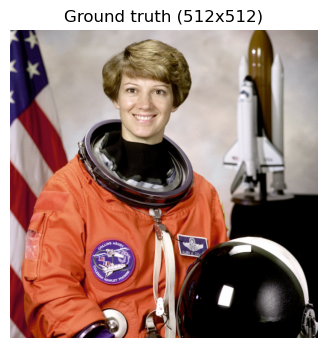

In [9]:
# IMAGE_PATH = "fence.png"       # <- set this to e.g. "/path/to/your/image.png"
IMAGE_PATH = None
DEMO_IMAGE = "astronaut"  # used only if IMAGE_PATH is None: "astronaut" (RGB) or "camera" (grayscale)

if IMAGE_PATH is not None:
    gt_image = image_to_tensor(IMAGE_PATH, device=device)
else:
    from skimage import data as skdata
    demo_fn = {"astronaut": skdata.astronaut, "camera": skdata.camera}[DEMO_IMAGE]
    gt_image = image_to_tensor(demo_fn(), device=device)  # astronaut: 512x512 RGB, camera: 512x512 grayscale

H, W = gt_image.shape[2], gt_image.shape[3]
print("Image tensor:", gt_image.shape)
plt.figure(figsize=(4, 4))
plt.imshow(gt_image[0].permute(1, 2, 0).cpu().numpy())
plt.title(f"Ground truth ({H}x{W})")
plt.axis("off")
plt.show()

## 4. Fit

`num_points`/`iterations` follow the paper's scale (up to ~50000 Gaussians,
50000 steps for full fidelity on Kodak-sized images -- Table 1). Lower these
for quicker experiments or smaller images.


In [20]:
import time

NUM_POINTS = 10000
ITERATIONS = 50000
SNAP_EVERY = 50   # 10 slow, 100 fast
LR = 1e-3
VERBOSE_EVERY = 500

losses = torch.empty(ITERATIONS, device=device)   # stays on GPU
snapshots, snap_iters = [], []

DECOMPOSITION = "RS"   # "RS" or "Cholesky"
BACKEND = "cuda"             # "cuda" (C++/CUDA kernels) or "torch" (pure PyTorch)
ModelClass = {"Cholesky": GaussianImage_Cholesky, "RS": GaussianImage_RS}[DECOMPOSITION]

model = ModelClass(
    num_points=NUM_POINTS, H=H, W=W,
    BLOCK_H=16, BLOCK_W=16, device=device, lr=LR, backend=BACKEND,
).to(device)

torch.cuda.synchronize(); t0 = time.time()
for it in range(1, ITERATIONS + 1):
    image = model()["render"]
    loss = loss_fn(image, gt_image)
    if not torch.isfinite(loss):          # one sync per step
        raise RuntimeError(f"Non-finite loss at iter {it} — check cholesky elements.")
    loss.backward()
    model.optimizer.step()
    model.optimizer.zero_grad(set_to_none=True)
    model.scheduler.step()
    losses[it - 1] = loss.detach()

    if it == 1 or it % SNAP_EVERY == 0 or it == ITERATIONS:
        # reuse the render you already have; store as uint8 (4x smaller)
        snapshots.append((image.detach()[0].permute(1, 2, 0) * 255).byte().cpu().numpy())
        snap_iters.append(it)
    if it % VERBOSE_EVERY == 0 or it == ITERATIONS:
        l = loss.item()
        print(f"iter {it:5d}/{ITERATIONS} | loss {l:.5f} | PSNR {10*math.log10(1/l):.2f} dB")
torch.cuda.synchronize()
print(f"Fit time: {time.time() - t0:.1f} s")

loss_np = losses.cpu().numpy()
history = {"loss": loss_np.tolist(), "psnr": (10 * np.log10(1 / loss_np)).tolist(),
           "snapshot_iters": snap_iters, "snapshots": snapshots}

iter   500/50000 | loss 0.03406 | PSNR 14.68 dB
iter  1000/50000 | loss 0.00873 | PSNR 20.59 dB
iter  1500/50000 | loss 0.00537 | PSNR 22.70 dB
iter  2000/50000 | loss 0.00370 | PSNR 24.31 dB
iter  2500/50000 | loss 0.00269 | PSNR 25.69 dB
iter  3000/50000 | loss 0.00204 | PSNR 26.91 dB
iter  3500/50000 | loss 0.00160 | PSNR 27.96 dB
iter  4000/50000 | loss 0.00130 | PSNR 28.85 dB
iter  4500/50000 | loss 0.00109 | PSNR 29.61 dB
iter  5000/50000 | loss 0.00095 | PSNR 30.23 dB
iter  5500/50000 | loss 0.00084 | PSNR 30.76 dB
iter  6000/50000 | loss 0.00075 | PSNR 31.22 dB
iter  6500/50000 | loss 0.00069 | PSNR 31.62 dB
iter  7000/50000 | loss 0.00063 | PSNR 32.00 dB
iter  7500/50000 | loss 0.00059 | PSNR 32.33 dB
iter  8000/50000 | loss 0.00055 | PSNR 32.63 dB
iter  8500/50000 | loss 0.00052 | PSNR 32.88 dB
iter  9000/50000 | loss 0.00049 | PSNR 33.14 dB
iter  9500/50000 | loss 0.00046 | PSNR 33.37 dB
iter 10000/50000 | loss 0.00044 | PSNR 33.57 dB
iter 10500/50000 | loss 0.00042 | PSNR 3

In [21]:
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

# All learnable tensors (_xyz, _cholesky, _features_dc) share one dtype;
# grab it off any of them rather than assuming float32.
param_dtype = next(p.dtype for p in model.parameters() if p.requires_grad)
bytes_per_param = torch.finfo(param_dtype).bits // 8
model_bytes = total_params * bytes_per_param

# Original image, as raw uncompressed pixels: H*W*3 channels, 1 byte/channel
# (standard 8-bit-per-channel storage, the same basis JPEG/PNG start from).
image_bytes = H * W * 3

print(f"Total learnable parameters: {total_params:,}")
print(f"Parameter dtype: {param_dtype} ({bytes_per_param} bytes/param)")
print(f"Model size: {model_bytes:,} bytes ({model_bytes / 1024:.1f} KB)")
print(f"Original image (raw, 8-bit/channel): {image_bytes:,} bytes ({image_bytes / 1024:.1f} KB)")
print(f"Model / image size ratio: {model_bytes / image_bytes:.2f}x")

Total learnable parameters: 80,000
Parameter dtype: torch.float32 (4 bytes/param)
Model size: 320,000 bytes (312.5 KB)
Original image (raw, 8-bit/channel): 786,432 bytes (768.0 KB)
Model / image size ratio: 0.41x


## 5. Loss & PSNR over iterations

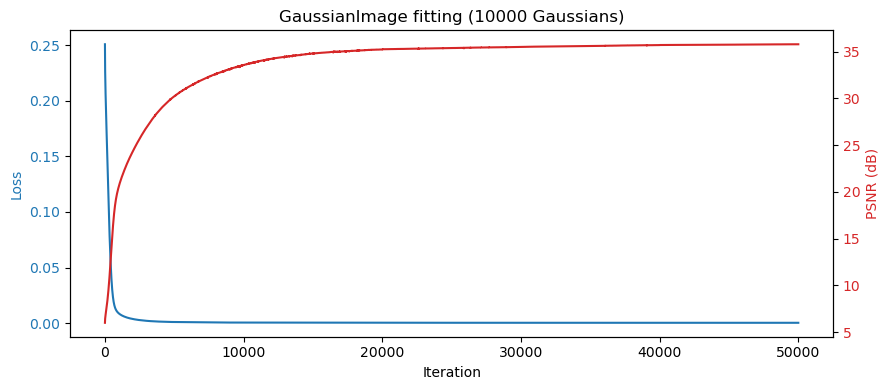

In [22]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(history["loss"], color="tab:blue")
ax1.set_xlabel("Iteration")
ax1.set_ylabel("Loss", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(history["psnr"], color="tab:red")
ax2.set_ylabel("PSNR (dB)", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")

plt.title(f"GaussianImage fitting ({model.init_num_points} Gaussians)")
fig.tight_layout()
plt.show()

## 6. Ground truth vs. final reconstruction

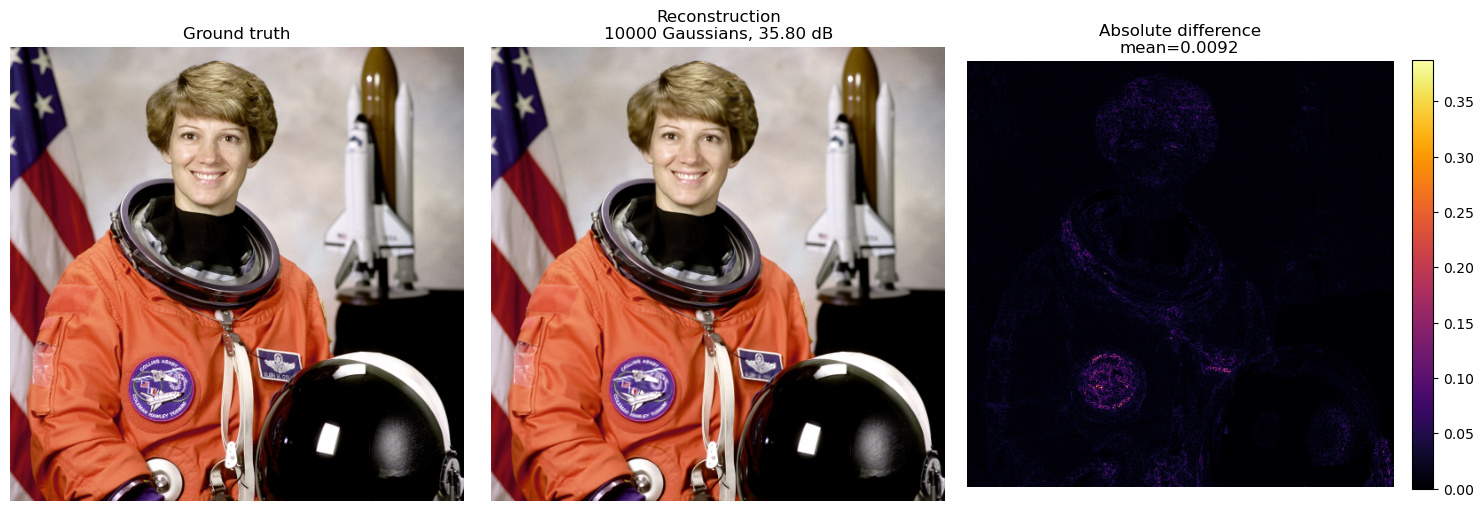

In [23]:
with torch.no_grad():
    final_render = model()["render"][0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()
gt_np = gt_image[0].permute(1, 2, 0).cpu().numpy()

diff = np.abs(gt_np - final_render)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(gt_np)
axes[0].set_title("Ground truth")
axes[0].axis("off")
axes[1].imshow(final_render)
axes[1].set_title(f"Reconstruction\n{model.init_num_points} Gaussians, {history['psnr'][-1]:.2f} dB")
axes[1].axis("off")
im = axes[2].imshow(diff.mean(axis=-1), cmap="inferno")
axes[2].set_title(f"Absolute difference\nmean={diff.mean():.4f}")
axes[2].axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 7. (Optional) Reconstruction progress across training

In [24]:
def make_snapshot_video(history, out_path="training.mp4", fps=10, dpi=120):
    snapshots   = history["snapshots"]      # (N, H, W, 3)
    snap_iters  = history["snapshot_iters"] # (N,)
    psnr        = history["psnr"]

    fig, ax = plt.subplots(figsize=(4, 4.4))
    im = ax.imshow(snapshots[0])
    ax.axis("off")
    title = ax.set_title("", fontsize=11)
    plt.tight_layout()

    writer = FFMpegWriter(fps=fps, metadata={"title": "training"}, bitrate=4000)

    with writer.saving(fig, out_path, dpi=dpi):
        for i in range(len(snapshots)):
            it = snap_iters[i]
            im.set_data(snapshots[i])
            title.set_text(f"it {it}  |  {psnr[it - 1]:.2f} dB")
            writer.grab_frame()

    plt.close(fig)
    print(f"Saved video to {out_path}")

# usage
import matplotlib as mpl
import imageio_ffmpeg

mpl.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()

# now your existing make_snapshot_video(...) call will work
make_snapshot_video(history, out_path="nov_14_pure_cuda_acclerated.mp4", fps=50)

Saved video to nov_14_pure_cuda_acclerated.mp4


## 8. Unified Video of Different Number of Blobs

In [26]:
import time

NUM_POINTS_LIST = [200, 1000, 10000]
ITERATIONS = 30000
SNAP_EVERY = 30      # 501 frames per run over 20,000 iterations
LR = 1e-3
VERBOSE_EVERY = 1000

DECOMPOSITION = "Cholesky"   # "RS" or "Cholesky"
BACKEND = "cuda"             # "cuda" (C++/CUDA kernels) or "torch" (pure PyTorch)
ModelClass = {"Cholesky": GaussianImage_Cholesky, "RS": GaussianImage_RS}[DECOMPOSITION]

models = {}
histories = {}

for n in NUM_POINTS_LIST:
    print(f"\n=== Fitting {n} Gaussians ===")

    model = ModelClass(
        num_points=n, H=H, W=W,
        BLOCK_H=16, BLOCK_W=16, device=device, lr=LR, backend=BACKEND,
    ).to(device)

    losses = torch.empty(ITERATIONS, device=device)   # stays on GPU
    snapshots, snap_iters = [], []

    torch.cuda.synchronize(); t0 = time.time()
    for it in range(1, ITERATIONS + 1):
        image = model()["render"]
        loss = loss_fn(image, gt_image)
        if not torch.isfinite(loss):          # one sync per step
            raise RuntimeError(f"[{n} Gaussians] Non-finite loss at iter {it} — check covariance.")
        loss.backward()
        model.optimizer.step()
        model.optimizer.zero_grad(set_to_none=True)
        model.scheduler.step()
        losses[it - 1] = loss.detach()

        if it == 1 or it % SNAP_EVERY == 0 or it == ITERATIONS:
            # reuse the render you already have; store as uint8 (4x smaller)
            snapshots.append((image.detach()[0].permute(1, 2, 0) * 255).byte().cpu().numpy())
            snap_iters.append(it)
        if it % VERBOSE_EVERY == 0 or it == ITERATIONS:
            l = loss.item()
            print(f"iter {it:5d}/{ITERATIONS} | loss {l:.5f} | PSNR {10*math.log10(1/l):.2f} dB")
    torch.cuda.synchronize()
    print(f"Fit time ({n} Gaussians): {time.time() - t0:.1f} s")

    loss_np = losses.cpu().numpy()
    histories[n] = {"loss": loss_np.tolist(), "psnr": (10 * np.log10(1 / loss_np)).tolist(),
                    "snapshot_iters": snap_iters, "snapshots": snapshots}
    models[n] = model

    del model, losses
    torch.cuda.empty_cache()


=== Fitting 200 Gaussians ===
iter  1000/30000 | loss 0.27941 | PSNR 5.54 dB
iter  2000/30000 | loss 0.23018 | PSNR 6.38 dB
iter  3000/30000 | loss 0.16901 | PSNR 7.72 dB
iter  4000/30000 | loss 0.10541 | PSNR 9.77 dB
iter  5000/30000 | loss 0.06822 | PSNR 11.66 dB
iter  6000/30000 | loss 0.05287 | PSNR 12.77 dB
iter  7000/30000 | loss 0.04627 | PSNR 13.35 dB
iter  8000/30000 | loss 0.04231 | PSNR 13.74 dB
iter  9000/30000 | loss 0.03872 | PSNR 14.12 dB
iter 10000/30000 | loss 0.03506 | PSNR 14.55 dB
iter 11000/30000 | loss 0.03083 | PSNR 15.11 dB
iter 12000/30000 | loss 0.02567 | PSNR 15.91 dB
iter 13000/30000 | loss 0.02088 | PSNR 16.80 dB
iter 14000/30000 | loss 0.01733 | PSNR 17.61 dB
iter 15000/30000 | loss 0.01468 | PSNR 18.33 dB
iter 16000/30000 | loss 0.01319 | PSNR 18.80 dB
iter 17000/30000 | loss 0.01220 | PSNR 19.14 dB
iter 18000/30000 | loss 0.01159 | PSNR 19.36 dB
iter 19000/30000 | loss 0.01119 | PSNR 19.51 dB
iter 20000/30000 | loss 0.01088 | PSNR 19.63 dB
iter 21000/30

In [27]:
mpl.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()

def make_combined_video(histories, num_points_list, gt_image,
                         out_path="training_combined.mp4", fps=50, dpi=120):
    """
    histories: dict {num_points: history}, one entry per run in num_points_list.
    All runs must share the same iterations/log_every so their snapshot
    timelines line up frame-for-frame. Lays them out 1xN, with a static
    ground-truth panel appended last.
    """
    gt_np = gt_image[0].clamp(0, 1).permute(1, 2, 0).cpu().numpy()

    n_frames = len(histories[num_points_list[0]]["snapshots"])
    for n in num_points_list:
        assert len(histories[n]["snapshots"]) == n_frames, (
            f"Run with {n} points has {len(histories[n]['snapshots'])} snapshots, "
            f"expected {n_frames} — every run must use the same iterations/log_every."
        )
    snap_iters = histories[num_points_list[0]]["snapshot_iters"]

    n_panels = len(num_points_list) + 1
    fig, axes = plt.subplots(1, n_panels, figsize=(3.2 * n_panels, 3.6))

    ims, titles = [], []
    for ax, n in zip(axes[:-1], num_points_list):
        im = ax.imshow(histories[n]["snapshots"][0])
        ax.axis("off")
        titles.append(ax.set_title("", fontsize=10))
        ims.append(im)

    axes[-1].imshow(gt_np)
    axes[-1].set_title("Ground truth", fontsize=10)
    axes[-1].axis("off")

    plt.tight_layout()
    writer = FFMpegWriter(fps=fps, metadata={"title": "training_combined"}, bitrate=6000)

    with writer.saving(fig, out_path, dpi=dpi):
        for i in range(n_frames):
            it = snap_iters[i]
            for im_, t_, n in zip(ims, titles, num_points_list):
                im_.set_data(histories[n]["snapshots"][i])
                psnr = histories[n]["psnr"][it - 1]
                t_.set_text(f"{n} Gaussians | it {it} | {psnr:.2f} dB")
            writer.grab_frame()

    plt.close(fig)
    print(f"Saved combined video to {out_path}")

make_combined_video(
    histories, NUM_POINTS_LIST, gt_image,
    out_path="training_combined_200_1000_10000_v5.mp4",
    fps=50,
)

Saved combined video to training_combined_200_1000_10000_v5.mp4
